# Exercício 5 · Projeto Integrado de Limpeza
**Ciência de Dados — Preparação dos Dados (CRISP-DM)**
**Aluno(a):** ____________________

**Base:** Dirty E-Commerce Data — SHEIN (Kaggle). São 21 arquivos CSV, um por categoria de produto, coletados do site por *web scraping*.

**Arquivos escolhidos:** `us-shein-shoes-4381.csv` (**calçados**) e `us-shein-sports_and_outdoors-3853.csv` (**esportes e lazer**). Escolhi os dois porque têm as colunas de que a minha pergunta precisa (ranking e número de cores), mas com **esquemas diferentes**: o de esportes tem duas colunas a mais (`blackfridaybelts-*`). Além disso, os dois compartilham produtos (tênis aparecem nas duas categorias), o que cria um problema de duplicata entre arquivos.

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.width = 160
pd.options.display.max_columns = 30
pd.options.display.max_colwidth = 50
sns.set_style('whitegrid')

## Pergunta de negócio
> **Em calçados e artigos esportivos, os produtos que oferecem mais opções de cor aparecem mais no ranking de "Best Sellers"? Essa relação muda com a faixa de preço?**

O que essa pergunta exige da limpeza:
- **ranking** e **número de cores** em formato numérico, e uma regra clara para o que significa cada valor vazio;
- **preço** numérico e confiável, para montar faixas;
- **cada produto contado uma vez**, senão um produto repetido conta várias vezes na taxa de "está no ranking";
- **textos padronizados**, porque o texto do ranking e os títulos vêm escritos de formas diferentes.

In [2]:
# CARREGAMENTO DOS ARQUIVOS
arquivos = sorted(glob.glob('*.csv'))
print(len(arquivos), 'arquivos encontrados')

def nome_categoria(caminho):
    # 'us-shein-sports_and_outdoors-3853.csv' -> 'sports_and_outdoors'
    return os.path.basename(caminho).split('-')[2]

escolhidos = [a for a in arquivos if nome_categoria(a) in ('shoes', 'sports_and_outdoors')]
bruto = {nome_categoria(a): pd.read_csv(a) for a in escolhidos}
for nome, d in bruto.items():
    print(f'{nome:<22} {d.shape[0]:>5} linhas x {d.shape[1]:>2} colunas -> {list(d.columns)}')

21 arquivos encontrados
shoes                   4380 linhas x  9 colunas -> ['color-count', 'goods-title-link--jump', 'goods-title-link--jump href', 'rank-title', 'rank-sub', 'price', 'discount', 'selling_proposition', 'goods-title-link']
sports_and_outdoors     3852 linhas x 11 colunas -> ['color-count', 'blackfridaybelts-bg src', 'blackfridaybelts-content', 'goods-title-link--jump', 'goods-title-link--jump href', 'rank-title', 'rank-sub', 'price', 'discount', 'selling_proposition', 'goods-title-link']


In [3]:
bruto['shoes'].head(4)

,color-count,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,discount,selling_proposition,goods-title-link
0,18.00,"Korean Style Casual Flat Sandals Women Shoes, ...",https://us.shein.com/Korean-Style-Casual-Flat-...,#1 Best Seller,In Beige Women Sandals,$5.25,-50%,NaN,NaN
1,8.00,"Sports Shoes, Street Sports Shoes, Men's And W...",https://us.shein.com/Sports-Shoes-Street-Sport...,#1 Best Seller,In Black and White Men Sneakers,$88.70,-24%,NaN,NaN
2,4.00,"New Style Plush Slippers With Toe, Thick Sole ...",https://us.shein.com/New-Style-Plush-Slippers-...,#1 Best Seller,In Hot Pink Women Home Slippers,$52.70,-21%,NaN,NaN
3,5.00,New Arrival Women's Pointed Toe Shallow Mouth ...,https://us.shein.com/New-Arrival-Women-s-Point...,#2 Best Seller,In Blue Women Pumps,$22.40,-19%,NaN,NaN


In [4]:
# DIAGNÓSTICO INICIAL (REGISTRAR PROBLEMAS ANTES DE CORRIGIR)
for nome, d in bruto.items():
    print('=' * 70, '\n', nome.upper())
    display(pd.DataFrame({'tipo': d.dtypes.astype(str), 'nulos': d.isna().sum(),
                          '% nulos': d.isna().mean() * 100, 'exemplo': d.apply(lambda s: s.dropna().iloc[0])}))

 SHOES


,tipo,nulos,% nulos,exemplo
color-count,float64,2200,50.23,18.00
goods-title-link--jump,str,4341,99.11,"Korean Style Casual Flat Sandals Women Shoes, ..."
goods-title-link--jump href,str,4341,99.11,https://us.shein.com/Korean-Style-Casual-Flat-...
rank-title,str,3106,70.91,#1 Best Seller
rank-sub,str,3106,70.91,In Beige Women Sandals
price,str,0,0.00,$5.25
discount,str,131,2.99,-50%
selling_proposition,str,1581,36.10,10+ sold recently
goods-title-link,str,39,0.89,Women's Fashion Plus Size Casual Outdoor Flat ...


 SPORTS_AND_OUTDOORS


,tipo,nulos,% nulos,exemplo
color-count,float64,2637,68.46,5.00
blackfridaybelts-bg src,str,2281,59.22,https://img.ltwebstatic.com/images3_ccc/2023/1...
blackfridaybelts-content,str,2281,59.22,Save $5.24
goods-title-link--jump,str,3813,98.99,"3pcs/Set Women Seamless Yoga Shorts, High Wais..."
goods-title-link--jump href,str,3813,98.99,https://us.shein.com/3pcs-Set-Women-Seamless-Y...
rank-title,str,2666,69.21,#9 Best Sellers
rank-sub,str,2666,69.21,in Women Sports Shorts
price,str,0,0.00,$7.85
discount,str,627,16.28,-40%
selling_proposition,str,1359,35.28,3.1k+ sold recently


In [5]:
# Lista de verificações feitas ANTES de mexer nos dados
def titulo_bruto(d):
    return d['goods-title-link'].fillna(d['goods-title-link--jump']) if 'goods-title-link--jump' in d else d['goods-title-link']

checagens = {}
for nome, d in bruto.items():
    t = titulo_bruto(d)
    checagens[nome] = {
        'cópias exatas (linha inteira)': d.duplicated().sum(),
        'mesmo título + preço': (d.assign(_t=t).duplicated(['_t', 'price']) & t.notna()).sum(),
        "título só na coluna '--jump'": (d['goods-title-link'].isna() & t.notna()).sum(),
        'títulos com espaço duplo': t.str.contains(r'\s{2}', na=False).sum(),
        "rank-title 'Best Seller' (singular)": d['rank-title'].str.endswith('Seller', na=False).sum(),
        "rank-title 'Best Sellers' (plural)": d['rank-title'].str.endswith('Sellers', na=False).sum(),
        "rank-sub começando com 'In' / 'in'": f"{d['rank-sub'].str.startswith('In ', na=False).sum()} / {d['rank-sub'].str.startswith('in ', na=False).sum()}",
        "preço é texto ('$...')": d['price'].dtype != float,
        'menor valor de color-count': d['color-count'].min(),
        'preço máximo (US$)': pd.to_numeric(d['price'].str.replace(r'[$,]', '', regex=True)).max(),
        'preço mediano (US$)': pd.to_numeric(d['price'].str.replace(r'[$,]', '', regex=True)).median(),
    }
display(pd.DataFrame(checagens))

# Produtos que aparecem nos DOIS arquivos
normaliza = lambda s: s.str.replace(r'\s+', ' ', regex=True).str.strip().str.lower()
em_comum = set(normaliza(titulo_bruto(bruto['shoes'])).dropna()) & set(normaliza(titulo_bruto(bruto['sports_and_outdoors'])).dropna())
print('Títulos presentes nos dois arquivos:', len(em_comum))

# color-count nos 21 arquivos: o menor valor é sempre 4?
cores_todos = pd.concat([pd.read_csv(a, usecols=lambda c: c == 'color-count')['color-count']
                         for a in arquivos if 'color-count' in pd.read_csv(a, nrows=0).columns])
print('color-count nos 21 arquivos -> mínimo:', cores_todos.min(), '| valores 1, 2 ou 3:', cores_todos.isin([1, 2, 3]).sum())

,shoes,sports_and_outdoors
cópias exatas (linha inteira),128,117
mesmo título + preço,173,221
título só na coluna '--jump',39,39
títulos com espaço duplo,136,147
rank-title 'Best Seller' (singular),966,136
rank-title 'Best Sellers' (plural),308,1050
rank-sub começando com 'In' / 'in',966 / 308,117 / 1069
preço é texto ('$...'),True,True
menor valor de color-count,4.00,4.00
preço máximo (US$),301.65,349.99


Títulos presentes nos dois arquivos: 360


color-count nos 21 arquivos -> mínimo: 4.0 | valores 1, 2 ou 3: 0


**Problemas encontrados (antes de qualquer correção)**

| # | Problema | Exemplo | Por que atrapalha a pergunta |
|---|---|---|---|
| 1 | **Números guardados como texto** | `price = '$14.20'`, `discount = '-21%'`, `rank-title = '#3 Best Seller'`, `selling_proposition = '1.2k+ sold recently'` | não dá para calcular faixas de preço nem posição no ranking |
| 2 | **Mesmo texto escrito de dois jeitos** | `'Best Seller'` x `'Best Sellers'`; `'In Women Flats'` x `'in Women Flats'` | categorias iguais seriam contadas como diferentes |
| 3 | **Espaços duplicados** nos títulos | `'Sandals  Women'` | impede reconhecer o mesmo produto |
| 4 | **Título em outra coluna** | 39 linhas por arquivo com título só em `goods-title-link--jump` | quem olha só `goods-title-link` acha que o produto não tem nome |
| 5 | **Duplicatas exatas e "quase exatas"** | mesmo título e preço, mas com ranking ou selo diferentes | um produto conta várias vezes na taxa de ranking |
| 6 | **Duplicatas entre arquivos** | 360 títulos aparecem em calçados **e** em esportes | ao juntar as categorias, o mesmo tênis é contado duas vezes |
| 7 | **Vazios com significados diferentes** | `rank-title` vazio = fora do ranking; `discount` vazio = sem desconto; `color-count` vazio = **menos de 4 cores** (o menor valor em todos os 21 arquivos é 4) | tratar tudo como "zero" ou apagar distorceria a resposta |
| 8 | **Esquemas diferentes** | esportes tem `blackfridaybelts-*`; outros arquivos não têm ranking ou cores | o pipeline precisa funcionar mesmo faltando colunas |
| 9 | **Preços extremos** | mediana de US$ 7 a 13, máximo de US$ 302 e 350 | distorcem médias e faixas |
| 10 | **Colunas sem utilidade para a pergunta** | links e imagens (`href`, `bg src`) | só ocupam espaço |

## Funções do pipeline
**Ordem de execução que escolhi e por quê:**
1. **`padronizar_textos`** primeiro: junta as colunas de título, tira espaços extras e unifica `Best Seller(s)` e `In/in`. Converter tipos e achar duplicatas depende de textos limpos (`'$1,199.00 '` com espaço não vira número; `'Tênis  X'` e `'Tênis X'` não seriam vistos como o mesmo produto). Também é aqui que eu escolho as colunas úteis e uniformizo o esquema.
2. **`corrigir_tipos`**: com o texto limpo, extraio os números.
3. **`tratar_duplicatas`**: antes dos ausentes, porque ao **consolidar** cópias do mesmo produto eu aproveito o que cada cópia tem (o melhor ranking, o maior selo de vendas). Se eu preenchesse os vazios antes, perderia essa informação.
4. **`tratar_ausentes`**: com cada produto já único, aplico a regra de cada coluna conforme o **significado** do vazio.
5. **`tratar_outliers`**: depois das duplicatas, para que cópias repetidas não pesem duas vezes no cálculo dos limites.
6. **`criar_features`**: por último, porque as faixas usam o preço já validado.

In [6]:
# FUNÇÕES DO PIPELINE
def coluna(df, nome):
    # devolve a coluna se ela existir no arquivo; senão, uma coluna vazia (arquivos têm esquemas diferentes)
    return df[nome] if nome in df.columns else pd.Series(pd.NA, index=df.index, dtype='string')

def limpar_texto(serie):
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip()

def para_numero(texto, padrao):
    # extrai o primeiro número que casa com o padrão e tira a vírgula de milhar ('1,199.00' -> 1199.0)
    return pd.to_numeric(texto.str.extract(padrao, expand=False).str.replace(',', '', regex=False),
                         errors='coerce').astype(float)


def padronizar_textos(df):
    # Esquema único + textos limpos. Colunas de link/imagem ficam de fora.
    out = pd.DataFrame(index=df.index)
    out['titulo'] = limpar_texto(coluna(df, 'goods-title-link')).fillna(limpar_texto(coluna(df, 'goods-title-link--jump')))
    out['titulo_chave'] = out['titulo'].str.lower()                          # usado só para comparar produtos
    out['preco_txt'] = limpar_texto(coluna(df, 'price'))
    out['desconto_txt'] = limpar_texto(coluna(df, 'discount'))
    out['vendas_txt'] = limpar_texto(coluna(df, 'selling_proposition'))
    out['ranking_txt'] = limpar_texto(coluna(df, 'rank-title')).str.replace(r'Best Sellers$', 'Best Seller', regex=True)
    out['ranking_categoria'] = limpar_texto(coluna(df, 'rank-sub')).str.replace(r'^in\s+', '', case=False, regex=True)
    out['economia_txt'] = limpar_texto(coluna(df, 'blackfridaybelts-content'))
    out['cores_txt'] = coluna(df, 'color-count')
    # guardo se o arquivo TINHA a coluna: "não existe no arquivo" é diferente de "vazio"
    out['arquivo_tem_ranking'] = 'rank-title' in df.columns
    out['arquivo_tem_cores'] = 'color-count' in df.columns
    return out


def corrigir_tipos(df):
    df = df.copy()
    df['preco'] = para_numero(df['preco_txt'], r'\$([\d,]+(?:\.\d+)?)')            # '$14.20' -> 14.2
    df['desconto_pct'] = para_numero(df['desconto_txt'], r'(\d+(?:\.\d+)?)%')       # '-21%'   -> 21.0
    milhar = df['vendas_txt'].str.contains('k+', regex=False).fillna(False).to_numpy(bool)
    df['vendas_min'] = para_numero(df['vendas_txt'], r'([\d.]+)k?\+') * np.where(milhar, 1000, 1)   # '1.2k+' -> 1200
    df['posicao_ranking'] = para_numero(df['ranking_txt'], r'#(\d+)').astype('Int64')               # '#3 Best Seller' -> 3
    df['economia_bf'] = para_numero(df['economia_txt'], r'\$([\d,]+(?:\.\d+)?)')     # 'Save $5.24' -> 5.24
    df['qtd_cores'] = pd.to_numeric(df['cores_txt'], errors='coerce').astype('Int64')
    return df.drop(columns=['preco_txt', 'desconto_txt', 'vendas_txt', 'ranking_txt', 'economia_txt', 'cores_txt'])


def tratar_duplicatas(df):
    # 1) cópias exatas saem; 2) linhas do mesmo produto (título + preço) são CONSOLIDADAS em uma só
    df = df.drop_duplicates()
    com_titulo, sem_titulo = df[df['titulo_chave'].notna()], df[df['titulo_chave'].isna()]
    regras = {c: 'first' for c in df.columns if c not in ('titulo_chave', 'preco')}   # first = 1º valor não vazio
    regras.update({'posicao_ranking': 'min', 'vendas_min': 'max', 'qtd_cores': 'max'})  # melhor posição, maior selo
    grupos = com_titulo.groupby(['titulo_chave', 'preco'], dropna=False, sort=False)
    juntos = grupos.agg(regras)
    juntos['vezes_listado'] = grupos.size()
    juntos = juntos.reset_index()
    return pd.concat([juntos, sem_titulo.assign(vezes_listado=1)], ignore_index=True)


def tratar_ausentes(df):
    # cada vazio é tratado conforme o que ele SIGNIFICA (ver tabela do relatório)
    df = df[df['titulo'].notna() & (df['preco'] > 0)].copy()                       # sem título ou preço válido não há produto
    df['tem_desconto'] = df['desconto_pct'].notna()
    df['desconto_pct'] = df['desconto_pct'].fillna(0)                               # sem selo de desconto = preço cheio
    df['no_ranking'] = df['posicao_ranking'].notna().astype('boolean').where(df['arquivo_tem_ranking'])
    # vendas_min, qtd_cores e posicao_ranking ficam com NA de propósito:
    #   vendas vazia = "menos de 10 vendidos ou sem selo" (não é zero); cores vazia = "menos de 4" (vira faixa em criar_features)
    return df


def tratar_outliers(df, corte=3.5):
    # z-score ROBUSTO (mediana e MAD) no log do preço; não apaga nada: marca e cria uma versão limitada
    df = df.copy()
    log_preco = np.log(df['preco'])
    centro = log_preco.median()
    mad = (log_preco - centro).abs().median()
    z_robusto = 0.6745 * (log_preco - centro) / mad
    df['preco_extremo'] = z_robusto.abs() > corte
    limite_inf, limite_sup = np.exp(centro - corte * mad / 0.6745), np.exp(centro + corte * mad / 0.6745)
    df['preco_ajustado'] = df['preco'].clip(limite_inf, limite_sup)
    return df


def criar_features(df):
    df = df.copy()
    cores = df['qtd_cores'].astype(float).fillna(1).where(df['arquivo_tem_cores'])     # vazio = menos de 4 cores
    df['faixa_cores'] = pd.cut(cores, bins=[0, 3, 6, 10, np.inf], labels=['menos de 4', '4 a 6', '7 a 10', '11 ou mais'])
    df['faixa_preco'] = pd.cut(df['preco'], bins=[0, 5, 15, 30, np.inf], labels=['até $5', '$5 a 15', '$15 a 30', 'acima de $30'])
    df['preco_cheio'] = df['preco'] / (1 - df['desconto_pct'] / 100)
    df['top3_ranking'] = (df['posicao_ranking'] <= 3).fillna(False).astype('boolean').where(df['arquivo_tem_ranking'])
    return df

## Execução do pipeline
A função `pipeline()` chama as etapas na ordem acima e anota quantas linhas cada uma mexeu.

In [7]:
# EXECUÇÃO DO PIPELINE
def pipeline(df_bruto, categoria):
    log = {'categoria': categoria, 'linhas brutas': len(df_bruto), 'cópias exatas no bruto': int(df_bruto.duplicated().sum())}
    df = padronizar_textos(df_bruto)
    df = corrigir_tipos(df)
    n = len(df); df = tratar_duplicatas(df); log['linhas consolidadas (duplicatas)'] = n - len(df)
    n = len(df); df = tratar_ausentes(df);   log['removidas (sem título/preço)'] = n - len(df)
    df = tratar_outliers(df);                log['preços extremos marcados'] = int(df['preco_extremo'].sum())
    df = criar_features(df)
    df.insert(0, 'categoria', categoria)
    log['linhas finais'] = len(df)
    return df.reset_index(drop=True), log

limpo, logs = {}, []
for nome, d in bruto.items():
    limpo[nome], log = pipeline(d, nome)
    logs.append(log)
pd.DataFrame(logs).set_index('categoria').T

categoria,shoes,sports_and_outdoors
linhas brutas,4380,3852
cópias exatas no bruto,128,117
linhas consolidadas (duplicatas),173,221
removidas (sem título/preço),0,0
preços extremos marcados,133,23
linhas finais,4207,3631


In [8]:
limpo['sports_and_outdoors'].sample(4, random_state=5).T

,603,1437,2024,2099
categoria,sports_and_outdoors,sports_and_outdoors,sports_and_outdoors,sports_and_outdoors
titulo_chave,tennis basic wide waistband pleated sports sko...,1pc outdoor solar powered cartoon mushroom hou...,tennis basic wide waistband sports skort,women's high waist body shaping underwear bottoms
preco,7.64,6.66,6.89,8.49
titulo,Tennis Basic Wide Waistband Pleated Sports Sko...,1pc Outdoor Solar Powered Cartoon Mushroom Hou...,Tennis Basic Wide Waistband Sports Skort,Women's High Waist Body Shaping Underwear Bottoms
ranking_categoria,Women Sports Skirts & Skorts,<NA>,<NA>,<NA>
arquivo_tem_ranking,True,True,True,True
arquivo_tem_cores,True,True,True,True
desconto_pct,25.00,30.00,25.00,7.00
vendas_min,NaN,200.00,"3,200.00","6,600.00"
posicao_ranking,10,<NA>,<NA>,<NA>


In [9]:
# Onde ficaram os limites de preço "extremo" e para que lado estão os extremos?
pd.DataFrame({nome: {'limite inferior (US$)': d['preco_ajustado'].min(), 'limite superior (US$)': d['preco_ajustado'].max(),
                     'extremos baratos': int((d['preco_extremo'] & (d['preco'] < d['preco'].median())).sum()),
                     'extremos caros': int((d['preco_extremo'] & (d['preco'] > d['preco'].median())).sum()),
                     'exemplo de extremo barato': d.loc[d['preco_extremo'] & (d['preco'] < d['preco'].median()), 'titulo'].iloc[0][:45]}
              for nome, d in limpo.items()})

,shoes,sports_and_outdoors
limite inferior (US$),1.53,0.39
limite superior (US$),105.55,115.23
extremos baratos,126,8
extremos caros,7,15
exemplo de extremo barato,"2pcs Sandals Non-Slip Stickers, Forefoot Pads",Street 1pc Matching Father And Daughter Keyri


In [10]:
# Validação cruzada: o desconto convertido bate com o "Save $x" da Black Friday?
esp = limpo['sports_and_outdoors']
tem_os_dois = esp['economia_bf'].notna() & esp['tem_desconto']
diferenca = (esp['preco_cheio'] - esp['preco'] - esp['economia_bf'])[tem_os_dois].abs()
print(f'Produtos com desconto e selo "Save": {tem_os_dois.sum()} | diferença entre economia calculada e informada: '
      f'mediana US$ {diferenca.median():.2f}, máxima US$ {diferenca.max():.2f}')

# Checagens finais de qualidade
for nome, d in limpo.items():
    print(f"{nome:<22} nulos em titulo/preco: {d[['titulo', 'preco']].isna().sum().sum()} | preços <= 0: {(d['preco'] <= 0).sum()} | "
          f"desconto fora de 0–100: {(~d['desconto_pct'].between(0, 100)).sum()} | título+preço repetidos: {d.duplicated(['titulo_chave', 'preco']).sum()}")

Produtos com desconto e selo "Save": 1490 | diferença entre economia calculada e informada: mediana US$ 0.00, máxima US$ 0.27
shoes                  nulos em titulo/preco: 0 | preços <= 0: 0 | desconto fora de 0–100: 0 | título+preço repetidos: 0
sports_and_outdoors    nulos em titulo/preco: 0 | preços <= 0: 0 | desconto fora de 0–100: 0 | título+preço repetidos: 0


**Validação:** a economia calculada a partir do desconto convertido (`preço cheio − preço`) bate com o valor que o site mostra na faixa "Save $x" (diferença de centavos, por arredondamento). Isso confirma que a conversão de `discount` e `price` está certa. As checagens finais não acham nulos nas colunas obrigatórias, preços inválidos, descontos fora da faixa nem produtos repetidos.

In [11]:
# Duplicatas ENTRE arquivos: o mesmo produto em calçados e em esportes
juntos = pd.concat(limpo.values(), ignore_index=True)
chave = ['titulo_chave', 'preco']
juntos['em_duas_categorias'] = juntos.duplicated(chave, keep=False)
print('Linhas na base combinada:', len(juntos))
print('Produtos (título + preço) presentes nas duas categorias:', juntos[juntos['em_duas_categorias']].drop_duplicates(chave).shape[0])
print('Linhas da base combinada que são esses produtos:', juntos['em_duas_categorias'].sum())
juntos[juntos['em_duas_categorias']].sort_values(chave)[['categoria', 'titulo', 'preco', 'posicao_ranking', 'ranking_categoria']].head(6)

Linhas na base combinada: 7838
Produtos (título + preço) presentes nas duas categorias: 361
Linhas da base combinada que são esses produtos: 722


,categoria,titulo,preco,posicao_ranking,ranking_categoria
866,shoes,"/Sports Shoes, Street Sports Shoes, Men's And ...",88.70,10,Blue Men Shoes
5482,sports_and_outdoors,"/Sports Shoes, Street Sports Shoes, Men's And ...",88.70,10,Blue Men Shoes
518,shoes,1 Pair Forefoot Insert Cushion Pads For Women ...,1.80,1,Inserts & Insoles
4864,sports_and_outdoors,1 Pair Forefoot Insert Cushion Pads For Women ...,1.80,<NA>,<NA>
28,shoes,1 Pair Heel Grips Liner Cushions Inserts For L...,1.14,<NA>,<NA>
4971,sports_and_outdoors,1 Pair Heel Grips Liner Cushions Inserts For L...,1.14,<NA>,<NA>


**Decisão sobre as duplicatas entre arquivos:** **mantive** o produto nas duas categorias, porque para a minha pergunta (feita **por categoria**) ele realmente faz parte das duas vitrines, e às vezes até com rankings diferentes em cada uma. Mas marquei com `em_duas_categorias`, para que qualquer número **somando as categorias** (ex.: "total de produtos") desconte essas repetições.

In [12]:
# TABELA ANTES x DEPOIS
def qualidade_bruto(d):
    t = titulo_bruto(d)
    return {'linhas': len(d), 'colunas': d.shape[1], '% de células vazias': d.isna().mean().mean() * 100,
            'cópias exatas': int(d.duplicated().sum()), 'repetidos (título + preço)': int((d.assign(_t=t).duplicated(['_t', 'price']) & t.notna()).sum()),
            'colunas numéricas': d.select_dtypes('number').shape[1], 'tipo de price': str(d['price'].dtype),
            'tipo de discount': str(d['discount'].dtype), 'tipo do ranking': str(d['rank-title'].dtype)}

def qualidade_limpo(d):
    return {'linhas': len(d), 'colunas': d.shape[1], '% de células vazias': d.isna().mean().mean() * 100,
            'cópias exatas': int(d.duplicated().sum()), 'repetidos (título + preço)': int(d.duplicated(['titulo_chave', 'preco']).sum()),
            'colunas numéricas': d.select_dtypes('number').shape[1], 'tipo de price': str(d['preco'].dtype),
            'tipo de discount': str(d['desconto_pct'].dtype), 'tipo do ranking': str(d['posicao_ranking'].dtype)}

antes_depois = pd.concat({nome: pd.DataFrame({'antes': qualidade_bruto(bruto[nome]), 'depois': qualidade_limpo(limpo[nome])})
                          for nome in bruto}, axis=1)
antes_depois

shoes          sports_and_outdoors         
                           antes   depois               antes   depois
linhas                      4380     4207                3852     3631
colunas                        9       21                  11       21
% de células vazias        47.81    15.60               52.35    14.32
cópias exatas                128        0                 117        0
repetidos (título + preço)   173        0                 221        0
colunas numéricas              1        9                   1        9
tipo de price                str  float64                 str  float64
tipo de discount             str  float64                 str  float64
tipo do ranking              str    Int64                 str    Int64

In [13]:
# % de vazios nos campos que a pergunta usa, antes e depois
mapa = {'titulo': 'goods-title-link', 'preco': 'price', 'desconto_pct': 'discount', 'posicao_ranking': 'rank-title', 'qtd_cores': 'color-count'}
campos = []
for nome in bruto:
    for novo, antigo in mapa.items():
        campos.append({'arquivo': nome, 'campo': novo, '% vazio antes': bruto[nome][antigo].isna().mean() * 100,
                       '% vazio depois': limpo[nome][novo].isna().mean() * 100,
                       'tipo antes': str(bruto[nome][antigo].dtype), 'tipo depois': str(limpo[nome][novo].dtype)})
campos = pd.DataFrame(campos)
campos.set_index(['arquivo', 'campo'])

% vazio antes  % vazio depois tipo antes tipo depois
arquivo             campo                                                                
shoes               titulo                    0.89            0.00        str      string
                    preco                     0.00            0.00        str     float64
                    desconto_pct              2.99            0.00        str     float64
                    posicao_ranking          70.91           70.31        str       Int64
                    qtd_cores                50.23           50.53    float64       Int64
sports_and_outdoors titulo                    1.01            0.00        str      string
                    preco                     0.00            0.00        str     float64
                    desconto_pct             16.28            0.00        str     float64
                    posicao_ranking          69.21           68.63        str       Int64
                    qtd_cores                68.46           69.65    float64       Int64

**Como ler a tabela:** o número de linhas cai por causa das cópias exatas e da consolidação de repetidos (que vão a **zero** depois). Preço, desconto e ranking deixam de ser texto. O % de células vazias cai de 48% para 16% (calçados) e de 52% para 14% (esportes), mas, sendo honesto, boa parte dessa queda vem de ter descartado colunas quase vazias (links, `--jump`). Ele **não** chega a zero, e isso é proposital: `posicao_ranking` vazio quer dizer "fora do ranking" e `qtd_cores` vazio quer dizer "menos de 4 cores"; preencher com um número seria inventar. O que eu fiz foi transformar esses vazios em informação explícita (`no_ranking`, `faixa_cores`). O `titulo` vai a 0% vazio porque foi buscado também na coluna `--jump`, e `desconto_pct` vai a 0% porque vazio significa "sem desconto".

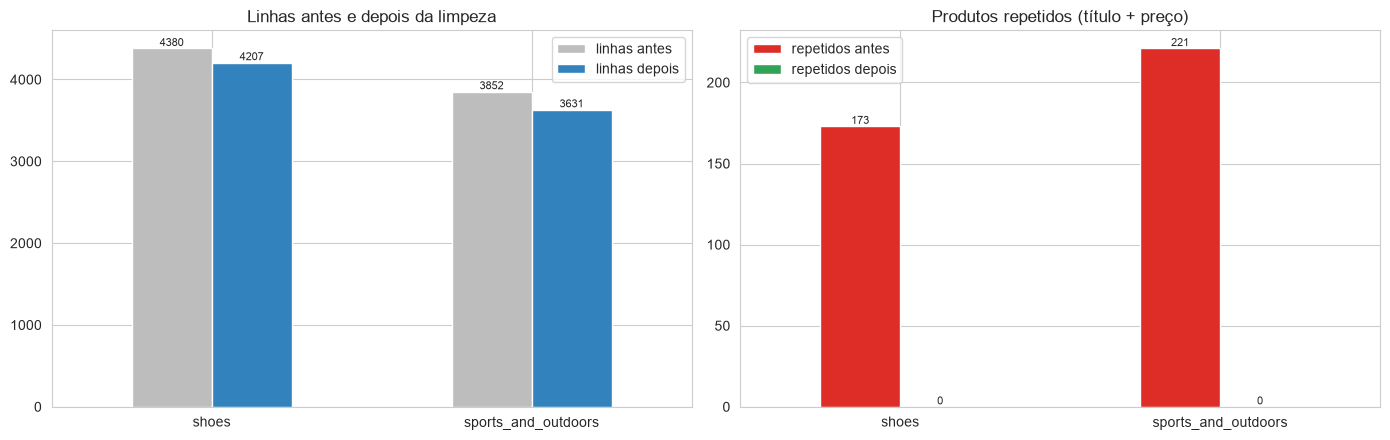

In [14]:
# VISUALIZAÇÕES — (1) linhas e repetições antes x depois
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
resumo_vis = pd.DataFrame({nome: {'linhas antes': qualidade_bruto(bruto[nome])['linhas'], 'linhas depois': qualidade_limpo(limpo[nome])['linhas'],
                                  'repetidos antes': qualidade_bruto(bruto[nome])['repetidos (título + preço)'],
                                  'repetidos depois': qualidade_limpo(limpo[nome])['repetidos (título + preço)']} for nome in bruto}).T
resumo_vis[['linhas antes', 'linhas depois']].plot.bar(ax=axes[0], rot=0, color=['#bdbdbd', '#3182bd'])
axes[0].set_title('Linhas antes e depois da limpeza')
resumo_vis[['repetidos antes', 'repetidos depois']].plot.bar(ax=axes[1], rot=0, color=['#de2d26', '#31a354'])
axes[1].set_title('Produtos repetidos (título + preço)')
for ax in axes:
    for barra in ax.containers:
        ax.bar_label(barra, fontsize=8)
plt.tight_layout()
plt.show()

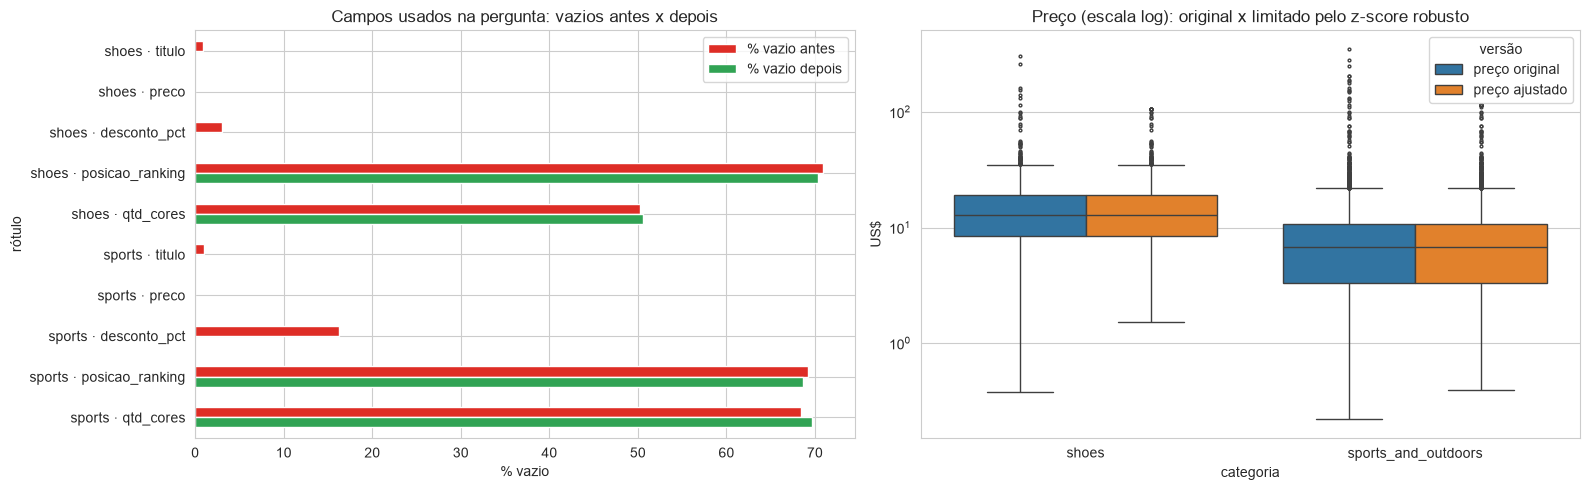

In [15]:
# VISUALIZAÇÕES — (2) campos-chave: % vazio antes x depois  e  (3) preço com e sem o tratamento de extremos
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
campos['rótulo'] = campos['arquivo'].str.split('_').str[0] + ' · ' + campos['campo']
campos.set_index('rótulo')[['% vazio antes', '% vazio depois']].plot.barh(ax=axes[0], color=['#de2d26', '#31a354'])
axes[0].invert_yaxis(); axes[0].set_xlabel('% vazio'); axes[0].set_title('Campos usados na pergunta: vazios antes x depois')

precos = pd.concat([pd.DataFrame({'categoria': d['categoria'], 'versão': 'preço original', 'US$': d['preco']}) for d in limpo.values()] +
                   [pd.DataFrame({'categoria': d['categoria'], 'versão': 'preço ajustado', 'US$': d['preco_ajustado']}) for d in limpo.values()])
sns.boxplot(data=precos, x='categoria', y='US$', hue='versão', ax=axes[1], flierprops={'markersize': 2})
axes[1].set_yscale('log'); axes[1].set_title('Preço (escala log): original x limitado pelo z-score robusto')
plt.tight_layout()
plt.show()

## Relatório e respostas às perguntas de reflexão
### Resposta à pergunta de negócio

produtos                     pct_no_ranking                    
categoria      shoes sports_and_outdoors          shoes sports_and_outdoors
faixa_cores                                                                
menos de 4      2126                2529          22.80               29.80
4 a 6            863                 592          34.80               31.20
7 a 10           527                 261          37.80               45.20
11 ou mais       691                 249          38.40               32.90

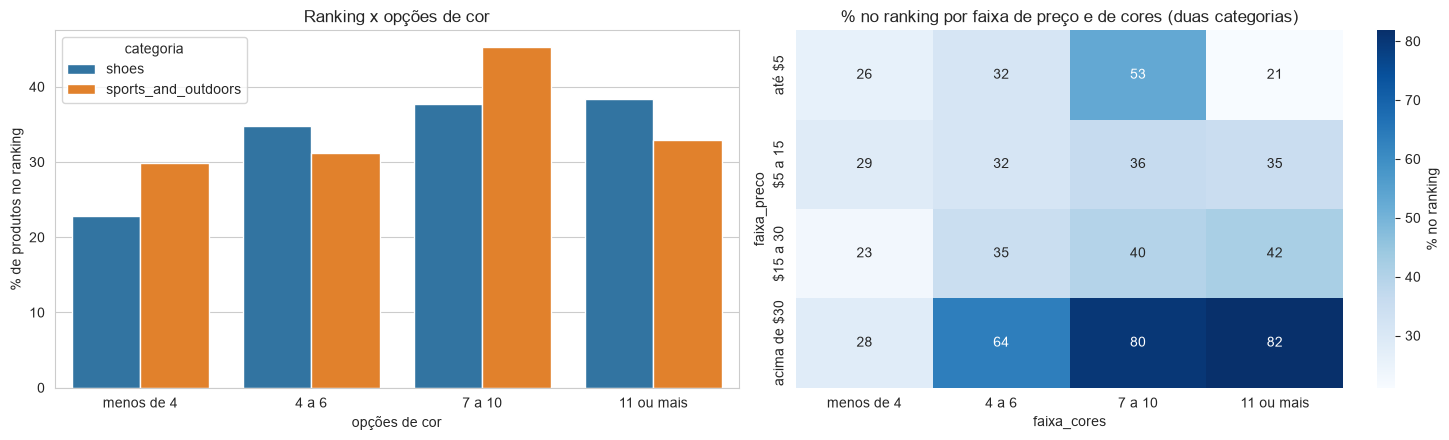

% no ranking por faixa de preço x cores:


faixa_cores,menos de 4,4 a 6,7 a 10,11 ou mais
faixa_preco,,,,
até $5,26.10,31.60,53.10,21.20
$5 a 15,28.70,31.50,36.40,35.30
$15 a 30,22.80,35.00,39.70,41.90
acima de $30,28.30,63.60,80.00,81.80


Produtos por faixa de preço x cores (para saber se cada célula tem amostra suficiente):


faixa_cores,menos de 4,4 a 6,7 a 10,11 ou mais
faixa_preco,,,,
até $5,1393,225,81,52
$5 a 15,2117,745,450,617
$15 a 30,1007,452,237,260
acima de $30,138,33,20,11


In [16]:
# RELATÓRIO E RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO — produtos com mais cores aparecem mais no ranking?
juntos['no_ranking_%'] = juntos['no_ranking'].astype(float) * 100          # True/False -> 100/0, para tirar médias
por_cores = (juntos.groupby(['categoria', 'faixa_cores'], observed=True)
                   .agg(produtos=('titulo', 'size'), pct_no_ranking=('no_ranking_%', 'mean')))
display(por_cores.unstack(0).round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=juntos, x='faixa_cores', y='no_ranking_%', hue='categoria', errorbar=None, ax=axes[0])
axes[0].set_ylabel('% de produtos no ranking'); axes[0].set_xlabel('opções de cor'); axes[0].set_title('Ranking x opções de cor')

tabela_preco = juntos.groupby(['faixa_preco', 'faixa_cores'], observed=True)['no_ranking_%'].mean().unstack()
sns.heatmap(tabela_preco, annot=True, fmt='.0f', cmap='Blues', ax=axes[1], cbar_kws={'label': '% no ranking'})
axes[1].set_title('% no ranking por faixa de preço e de cores (duas categorias)')
plt.tight_layout()
plt.show()

print('% no ranking por faixa de preço x cores:')
display(tabela_preco.round(1))
print('Produtos por faixa de preço x cores (para saber se cada célula tem amostra suficiente):')
pd.crosstab(juntos['faixa_preco'], juntos['faixa_cores'])

**Resposta:** sim, produtos com mais opções de cor aparecem mais no ranking, de forma clara em calçados e mais fraca em esportes.
- **Calçados:** a fatia de produtos no ranking sobe de **22,8%** (menos de 4 cores) para **34,8%** (4 a 6), **37,8%** (7 a 10) e **38,4%** (11 ou mais). A relação é positiva e cresce de forma consistente.
- **Esportes:** sobe de **29,8%** para 31,2% e **45,2%** (7 a 10), mas cai para 32,9% com 11 ou mais cores. A relação existe, mas é menos limpa, provavelmente porque a categoria mistura coisas em que a cor importa (roupas, tênis) com coisas em que não importa (garrafas, barracas, ventiladores).
- **Faixa de preço:** com as duas categorias juntas, ter 4 ou mais cores está ligado a mais ranking em quase todas as faixas. O efeito parece **maior nos produtos caros**: acima de US$ 30, 28% dos produtos com menos de 4 cores estão no ranking, contra 64% a 82% dos que têm 4 ou mais. Mas essas células têm só 11 a 33 produtos, então é um indício, não uma conclusão. Até US$ 5 o padrão é irregular.

**Ressalvas importantes:**
1. Isso é **associação, não causa**. Pode ser o contrário: o produto vende bem e por isso a loja lança mais cores.
2. "Menos de 4" junta produtos de 1, 2 e 3 cores, porque o site só mostra a contagem a partir de 4. Não dá para separar o produto de cor única.
3. O ranking é **por subcategoria** (ex.: "#3 Best Seller em Women Flats"); subcategorias pequenas facilitam entrar no top.
4. A base é uma "foto" do site tirada por scraping, não um histórico de vendas.

### Decisões tomadas e justificativas

| Etapa | O que fiz | Por quê | Impacto |
|---|---|---|---|
| Padronização de textos | Juntei `goods-title-link` com `--jump`; tirei espaços duplos; `Best Sellers` → `Best Seller`; tirei o `In/in` do começo de `rank-sub`; escolhi só as colunas úteis | Textos iguais escritos diferente impedem comparar e agrupar | Todo produto passa a ter título; esquema único para qualquer arquivo |
| Tipos | Preço, desconto, posição no ranking, vendas (`1.2k+` → 1200), cores e "Save $" viraram números | Sem número não há faixa de preço nem ranking | Ver tabela "antes x depois" |
| Duplicatas | Tirei cópias exatas e **consolidei** linhas do mesmo produto (título + preço), guardando a **melhor posição** e o **maior selo de vendas**; criei `vezes_listado` | O mesmo produto aparece em várias listas do site; apagar uma das cópias às cegas jogaria fora o ranking dela | 173 e 221 linhas a menos (128 e 117 eram cópias exatas); repetidos vão a zero |
| Duplicatas entre arquivos | Mantive nas duas categorias, com a marca `em_duas_categorias` | A pergunta é por categoria; para totais gerais, basta descontar | 361 produtos (722 linhas) marcados |
| Ausentes | `discount` vazio → 0 (e `tem_desconto`); `rank-title` vazio → `no_ranking = False`; `color-count` vazio → faixa "menos de 4"; vendas vazia fica NA; sem título ou preço → removida | Cada vazio quer dizer uma coisa diferente | Nenhuma imputação estatística |
| Coluna inexistente no arquivo | Se o arquivo não tem ranking ou cores, `no_ranking` e `faixa_cores` ficam **desconhecidos (NA)**, não falsos | "O arquivo não traz essa informação" é diferente de "o produto não está no ranking" | Evita conclusões erradas na base completa |
| Outliers | Z-score **robusto** (mediana e MAD) no **log** do preço, corte 3,5; marcar `preco_extremo` e criar `preco_ajustado`; **não apagar** | Preço é muito assimétrico; mediana e MAD não são puxadas pelos extremos; produto caro é real | 133 e 23 marcados; em calçados, 126 são baratos (adesivos, palmilhas) |
| Features | `faixa_cores`, `faixa_preco`, `no_ranking`, `top3_ranking`, `preco_cheio`, `vezes_listado` | Respondem diretamente à pergunta | 6 colunas novas |

### Reutilização: o mesmo pipeline nos 21 arquivos

In [17]:
# Sem alterar nenhuma função, aplico o pipeline a todos os arquivos
todos, registros = {}, []
for a in arquivos:
    nome = nome_categoria(a)
    try:
        todos[nome], log = pipeline(pd.read_csv(a), nome)
        log['status'] = 'ok'
    except Exception as erro:
        log = {'categoria': nome, 'status': f'ERRO: {erro!r}'}
    registros.append(log)

reg = pd.DataFrame(registros).set_index('categoria')
print('Arquivos processados sem erro:', (reg['status'] == 'ok').sum(), 'de', len(reg))
reg

Arquivos processados sem erro: 21 de 21


,linhas brutas,cópias exatas no bruto,linhas consolidadas (duplicatas),removidas (sem título/preço),preços extremos marcados,linhas finais,status
categoria,,,,,,,
appliances,3986,209,265,0,2,3721,ok
automotive,4109,179,257,0,86,3852,ok
baby_and_maternity,4432,18,48,0,9,4384,ok
bags_and_luggage,4298,31,87,0,5,4211,ok
beauty_and_health,4266,12,78,0,129,4188,ok
curve,2848,103,132,1,7,2715,ok
electronics,4394,34,133,0,220,4261,ok
home_and_kitchen,3719,176,199,0,33,3520,ok
home_textile,3882,188,239,0,11,3643,ok


In [18]:
base_completa = pd.concat(todos.values(), ignore_index=True)
print('Base completa:', base_completa.shape)
print('Categorias sem informação de ranking (no_ranking = NA):', sorted(base_completa.loc[base_completa['no_ranking'].isna(), 'categoria'].unique()))
print('Categorias sem informação de cores (faixa_cores = NA):', sorted(base_completa.loc[base_completa['faixa_cores'].isna(), 'categoria'].unique()))
print('\nMaiores preços da base completa (todos marcados como extremos?):')
display(base_completa.nlargest(3, 'preco')[['categoria', 'titulo', 'preco', 'preco_extremo', 'preco_ajustado']])

(base_completa.groupby('categoria')
    .agg(produtos=('titulo', 'size'), preco_mediano=('preco', 'median'), pct_com_desconto=('tem_desconto', 'mean'),
         pct_no_ranking=('no_ranking', 'mean'), pct_preco_extremo=('preco_extremo', 'mean'))
    .assign(pct_com_desconto=lambda t: t['pct_com_desconto'] * 100, pct_no_ranking=lambda t: t['pct_no_ranking'] * 100,
            pct_preco_extremo=lambda t: t['pct_preco_extremo'] * 100)
    .round(1))

Base completa: (78226, 21)
Categorias sem informação de ranking (no_ranking = NA): ['automotive', 'baby_and_maternity']
Categorias sem informação de cores (faixa_cores = NA): ['appliances', 'automotive', 'home_and_kitchen', 'jewelry_and_accessories', 'office_and_school_supplies', 'tools_and_home_improvement', 'toys_and_games']

Maiores preços da base completa (todos marcados como extremos?):


,categoria,titulo,preco,preco_extremo,preco_ajustado
31209,home_textile,This Is A Very Goods Product Name A A A A !!! ...,"888,888.00",True,131.28
3253,appliances,BOSSCARE Full Body Zero Gravity 4D Massage Cha...,"2,399.99",True,"2,101.24"
45168,office_and_school_supplies,Brunello Cucinelli Bags.. Dove Grey,"2,305.46",True,21.13


,produtos,preco_mediano,pct_com_desconto,pct_no_ranking,pct_preco_extremo
categoria,,,,,
appliances,3721,16.50,60.00,14.90,0.10
automotive,3852,3.40,33.30,<NA>,2.20
baby_and_maternity,4384,7.70,63.00,<NA>,0.20
bags_and_luggage,4211,5.50,96.70,9.50,0.10
beauty_and_health,4188,2.40,93.50,19.90,3.10
curve,2715,12.00,97.30,19.10,0.30
electronics,4261,2.30,34.80,17.20,5.20
home_and_kitchen,3520,2.60,42.80,30.10,0.90
home_textile,3643,6.50,37.60,13.70,0.30


**Resultado da reutilização:** o pipeline rodou nos **21 arquivos sem nenhum ajuste** e gerou uma base de 78.226 produtos. Pontos que só apareceram nesta etapa:
- `automotive` e `baby_and_maternity` não têm colunas de ranking: lá `no_ranking` ficou **desconhecido (NA)**, e não `False`. Sete arquivos não têm `color-count`, e `faixa_cores` também ficou NA. Se o pipeline tivesse preenchido com 0/`False`, esses arquivos apareceriam como "0% no ranking", o que seria falso.
- `toys_and_games` não tem a coluna `--jump`, então 12 produtos sem título nenhum foram removidos.
- O z-score robusto pegou casos que nenhuma regra fixa pegaria: um **produto de teste** em `home_textile` ("This Is A Very Goods Product Name A A A A !!!") com preço de **US$ 888.888**, e uma bolsa Brunello Cucinelli de US$ 2.305 cadastrada em **material de escritório**. Os dois ficaram marcados como extremos. O primeiro é claramente erro e deveria ser removido antes de qualquer análise de preço.

In [19]:
# Experimento para a reflexão 2: a ORDEM das etapas muda o resultado?
experimento = []
for nome, d in bruto.items():
    base = corrigir_tipos(padronizar_textos(d))

    # (a) outliers de DESCONTO (IQR): calculados antes de preencher os vazios x depois de preencher com 0
    def n_outliers_iqr(s):
        q1, q3 = s.quantile([0.25, 0.75])
        return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum()), q1, q3
    sem_preencher = n_outliers_iqr(base['desconto_pct'].dropna())
    preenchido = n_outliers_iqr(base['desconto_pct'].fillna(0))

    # (b) limites de preço extremo calculados antes x depois de consolidar duplicatas
    antes = tratar_outliers(base[base['preco'] > 0])
    depois = tratar_outliers(tratar_ausentes(tratar_duplicatas(base)))

    experimento.append({'arquivo': nome,
        'desconto: outliers (vazios ignorados)': sem_preencher[0], 'desconto: Q1 (vazios ignorados)': sem_preencher[1],
        'desconto: outliers (vazios = 0 antes)': preenchido[0], 'desconto: Q1 (vazios = 0 antes)': preenchido[1],
        'preço: limite sup. (antes das duplicatas)': antes['preco_ajustado'].max(), 'preço: extremos (antes)': int(antes['preco_extremo'].sum()),
        'preço: limite sup. (depois das duplicatas)': depois['preco_ajustado'].max(), 'preço: extremos (depois)': int(depois['preco_extremo'].sum())})
pd.DataFrame(experimento).set_index('arquivo').T

arquivo,shoes,sports_and_outdoors
desconto: outliers (vazios ignorados),612.00,87.00
desconto: Q1 (vazios ignorados),20.00,13.00
desconto: outliers (vazios = 0 antes),851.00,53.00
desconto: Q1 (vazios = 0 antes),20.00,7.00
preço: limite sup. (antes das duplicatas),105.55,113.37
preço: extremos (antes),139.00,25.00
preço: limite sup. (depois das duplicatas),105.55,115.23
preço: extremos (depois),133.00,23.00


### Respostas às perguntas de reflexão

**1. Qual problema foi o mais difícil de perceber? Por que passaria despercebido numa análise rápida?**
O **significado do `color-count` vazio**. À primeira vista ele parece um dado faltando comum (50% em calçados, 68% em esportes), e a reação automática seria apagar essas linhas ou preencher com a mediana (5 ou 6 cores). Só quando conferi o menor valor da coluna nos 21 arquivos percebi que ele **nunca é 1, 2 ou 3**: o mínimo é sempre 4. Ou seja, o site só mostra o selo "+N cores" a partir de 4, e o vazio quer dizer "**menos de 4 cores**". Preencher com a mediana daria 5 cores a produtos que têm uma só, e inverteria exatamente a resposta da minha pergunta de negócio. Um `isna().sum()` ou um `describe()` rápido não mostram isso; é preciso perguntar *por que* o valor está vazio.

Em segundo lugar, as **duplicatas entre arquivos**: 361 produtos estão em calçados e em esportes ao mesmo tempo. Olhando cada arquivo separado, elas são invisíveis; só aparecem quando se junta a base.

**2. A ordem das etapas importa? Exemplo em que tratar outliers antes dos ausentes (ou vice-versa) mudaria o resultado.**
Importa, e o experimento acima mostra com números:
- **Ausentes antes de outliers (no desconto):** se eu preencho os descontos vazios com 0 *antes* de procurar outliers pelo IQR, os zeros puxam o primeiro quartil para baixo. Em esportes, que tem 627 descontos vazios, o Q1 cai de 13% para 7% e o número de "descontos extremos" muda de **87 para 53**; em calçados, muda de **612 para 851**. Os mesmos dados, só com a ordem trocada, dão outliers diferentes.
- **Outliers antes dos ausentes (no preço):** se eu preenchesse preços vazios com a **média** antes de tratar os extremos, o produto de teste de US$ 888.888 somaria cerca de US$ 244 à média de `home_textile` (cuja mediana é US$ 6,50), e todo preço preenchido sairia absurdo.
- **Duplicatas antes de outliers:** antes de consolidar as repetições, calçados tinha 139 preços extremos; depois, 133. Em esportes, o limite superior passa de US$ 113 para US$ 115. Aqui o efeito é pequeno, porque há poucas repetições, mas um produto listado 5 vezes pesa 5 vezes na mediana e no MAD.

A regra que segui: primeiro o que é **forma** (texto, tipo, duplicata), depois o que é **falta** (ausentes) e por último o que é **estatística** (outliers e features), porque cada etapa calcula coisas que dependem das anteriores.

**3. Se a pergunta de negócio fosse outra, qual decisão eu mudaria?**
- **"Quanto cada categoria fatura?"** Deixar as vendas vazias como NA não serviria; eu precisaria de uma estimativa numérica (com a ressalva de que "100+" é só um mínimo). Também teria de **remover** as 361 duplicatas entre arquivos (senão o faturamento conta o mesmo tênis duas vezes) e usaria o preço **real**, não o `preco_ajustado`, removendo só erros claros como o produto de teste.
- **"Os descontos são de verdade?"** Não preencheria desconto vazio com 0, porque isso assume que o produto está pelo preço cheio. Manteria NA e usaria a coluna "Save $x" da Black Friday para conferir.
- **"Quais produtos aparecem em mais listas do site?"** A consolidação de duplicatas apagaria exatamente essa informação. Eu manteria uma linha por listagem (ou usaria a coluna `vezes_listado`, que criei pensando nisso).
- **"Qual o preço típico de um calçado?"** Os extremos de calçados são quase todos **baratos** (126 de 133: adesivos, palmilhas). Para essa pergunta, eu separaria os acessórios pelo tipo de produto, em vez de tratá-los como outliers de preço.